# Detailed Ablation Study — Synchronization Digital Twin / V5

This notebook runs controlled input/architecture ablations on the **existing V3 train/validation/test split**. It uses the project's `scripts/train_gnn_v5.py` and `scripts/controlled_experiments_revised.py` implementations rather than reimplementing V5.

## What this notebook tests

1. **Temporal history:** 8 snapshots (full input), 4 snapshots, and 1 snapshot.
2. **Graph relations:** full graph, without `waits_for`, without `owned_by`, and without both relations.
3. **Runtime feature group:** remove scheduler-related features while retaining node types, waiting state, wait duration and lock ownership.
4. **Auxiliary future-risk supervision:** include the already-run full-V5 vs no-risk-auxiliary-loss result in the final comparison when its result JSON is supplied.
5. **Existing controlled comparisons:** optionally include the already-run GraphSAGE+GRU baseline result.

**Important:** The newly trained variants are genuine retraining ablations. Thresholds are tuned on validation data only; the test set is used only for final evaluation. A single seed is an exploratory ablation, not a multi-seed statistical claim. For publication-quality confidence intervals, repeat selected variants with multiple seeds.

The ablations mask input information while preserving the original model dimensions. Therefore, they measure dependence on those inputs; they do not prove that the masked component is unnecessary in every deployment.


In [ ]:
# If running in Google Colab, mount Drive or clone your repository first.
# Expected repository layout:
# deadlockprediction/
#   dataset/v3/
#   scripts/train_gnn_v5.py
#   scripts/controlled_experiments_revised.py
#   outputs/gnn_v5/best_model_v5.pt (optional for reference)

from pathlib import Path
import os, sys, json, time, copy, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

SEED = 123
# Set this to the repository root if auto-detection does not find it.
CANDIDATE_ROOTS = [
    Path.cwd(),
    Path("../../deadlockprediction"),
    Path("/project1"),
    Path.home() / "deadlockprediction",
]
ROOT = next((p.resolve() for p in CANDIDATE_ROOTS
             if (p / "scripts" / "train_gnn_v5.py").exists()
             and (p / "dataset" / "v3").exists()), None)

if ROOT is None:
    raise FileNotFoundError(
        "Could not locate repository root. Set ROOT manually to the folder "
        "containing both scripts/train_gnn_v5.py and dataset/v3."
    )

sys.path.insert(0, str(ROOT / "scripts"))
from train_gnn_v5 import (
    LABELS, LABEL_TO_ID, TemporalSequenceDataset, TemporalRiskAwareV5,
    set_seed, calculate_metrics, tune_thresholds, hierarchical_predictions
)
try:
    from controlled_experiments_revised import (
        train_v5_variant, load_v5_checkpoint, evaluate_v5
    )
except ImportError:
    # Some repository versions use the shorter filename.
    from scripts.graphsagegrucomp_nofuturerisk_study import (
        train_v5_variant, load_v5_checkpoint, evaluate_v5
    )

# Seed-specific output directory
OUTPUT_DIR = ROOT / "outputs" / "detailed_ablation" / f"seed_{SEED}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Results will be saved in: {OUTPUT_DIR.resolve()}")
DATASET_DIR = ROOT / "dataset" / "v3"
OUTPUT_DIR = ROOT / "outputs" / "detailed_ablation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Repository:", ROOT)
print("Dataset:", DATASET_DIR)
print("Device:", DEVICE)
print("PyTorch:", torch.__version__)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Results will be saved in: /Users/ananyajain/Downloads/project1/deadlockprediction/outputs/detailed_ablation/seed_123
Repository: /Users/ananyajain/Downloads/project1/deadlockprediction
Dataset: /Users/ananyajain/Downloads/project1/deadlockprediction/dataset/v3
Device: cpu
PyTorch: 2.2.2


## 1. Experimental controls

All variants use the same data split, seed, hidden size, batch size, optimizer and stopping rule. Only the specified input view changes.

The default run is intentionally configurable. Graph ablations retrain V5 and can take a long time on CPU; a CUDA runtime is recommended. Start with one variant to verify the environment, then run the full list. The existing test split must not be used to choose variants or thresholds.


In [4]:
# Configuration — adjust before running the training cell.
SEED = 123
HIDDEN_SIZE = 32
BATCH_SIZE = 32
MAX_EPOCHS = 10
PATIENCE = 3
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

# Choose any subset. Each selected variant is trained from scratch.
# Options:
#   "full_8_snapshot_reference" (fresh full V5 retraining)
#   "history_4_snapshots"
#   "history_1_snapshot"
#   "no_waits_for_relation"
#   "no_owned_by_relation"
#   "no_graph_relations"
#   "no_scheduler_features"
RUN_VARIANTS = [
    "history_4_snapshots",
    "history_1_snapshot",
    "no_waits_for_relation",
    "no_owned_by_relation",
    "no_graph_relations",
    "no_scheduler_features",
]

# Optional JSON from the already-run controlled comparison, e.g.
# outputs/controlled_experiments/results.json
# Leave None if that file is elsewhere or you prefer to add the existing results manually later.
EXISTING_CONTROLLED_RESULTS = None

set_seed(SEED)
train_base = TemporalSequenceDataset(DATASET_DIR, "train")
val_base   = TemporalSequenceDataset(DATASET_DIR, "validation")
test_base  = TemporalSequenceDataset(DATASET_DIR, "test")

print(f"Train sequences: {len(train_base):,}")
print(f"Validation sequences: {len(val_base):,}")
print(f"Test sequences: {len(test_base):,}")
print("Test split used for training/selection: False")


Loading TRAIN snapshots...
Loading TRAIN sequences...
Loaded 215,051 snapshots
Loaded 51,236 sequences
Loading VALIDATION snapshots...
Loading VALIDATION sequences...
Loaded 45,872 snapshots
Loaded 5,570 sequences
Loading TEST snapshots...
Loading TEST sequences...
Loaded 45,786 snapshots
Loaded 5,549 sequences
Train sequences: 51,236
Validation sequences: 5,570
Test sequences: 5,549
Test split used for training/selection: False


## 2. Dataset wrappers for controlled input ablations

These wrappers preserve the labels and sequence metadata while applying one input change consistently to train, validation and test. They do not modify the original dataset files.

Feature indices follow the V5 9-dimensional representation:
- 0 `is_thread`
- 1 `is_lock`
- 2 `is_waiting`
- 3 normalized `wait_ns`
- 4 `has_owner`
- 5 normalized scheduler switches
- 6 normalized wakeups
- 7 normalized CPU migrations
- 8 normalized last CPU

The `no_scheduler_features` condition zeros indices 5–8. This retains graph structure and basic waiting/ownership evidence.


In [5]:
class AblationDataset:
    def __init__(self, base, *, history=None, remove_relations=(), zero_features=()):
        self.base = base
        self.labels = list(base.labels)
        self.sequences = []
        self.history = history
        self.remove_relations = set(remove_relations)
        self.zero_features = tuple(zero_features)

        for graphs, label, row in base.sequences:
            transformed = []
            selected_graphs = graphs[-history:] if history is not None else graphs
            for graph in selected_graphs:
                g = {
                    "x": graph["x"].clone(),
                    "edges": {rel: edge.clone() for rel, edge in graph["edges"].items()},
                }
                for rel in self.remove_relations:
                    if rel in g["edges"]:
                        g["edges"][rel] = torch.empty((2, 0), dtype=torch.long)
                if self.zero_features:
                    g["x"][:, list(self.zero_features)] = 0.0
                transformed.append(g)
            self.sequences.append((transformed, label, row))

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        return self.sequences[idx]


def make_variant(name, base):
    if name == "full_8_snapshot_reference":
        return AblationDataset(base, history=8)
    if name == "history_4_snapshots":
        return AblationDataset(base, history=4)
    if name == "history_1_snapshot":
        return AblationDataset(base, history=1)
    if name == "no_waits_for_relation":
        return AblationDataset(base, remove_relations=("waits_for",))
    if name == "no_owned_by_relation":
        return AblationDataset(base, remove_relations=("owned_by",))
    if name == "no_graph_relations":
        return AblationDataset(base, remove_relations=("waits_for", "owned_by"))
    if name == "no_scheduler_features":
        return AblationDataset(base, zero_features=(5, 6, 7, 8))
    raise ValueError(f"Unknown variant: {name}")


def describe_variant(name):
    descriptions = {
        "full_8_snapshot_reference": "Full 8-snapshot V5 input",
        "history_4_snapshots": "Last 4 snapshots only",
        "history_1_snapshot": "Last snapshot only (no temporal history)",
        "no_waits_for_relation": "Remove thread→lock waits_for edges",
        "no_owned_by_relation": "Remove lock→thread owned_by edges",
        "no_graph_relations": "Remove both relation types",
        "no_scheduler_features": "Zero scheduler/runtime features (x[5:9])",
    }
    return descriptions[name]


## 3. Train and evaluate the selected ablations

For each variant:
1. Train V5 from a fresh initialization.
2. Select the checkpoint using the existing validation-based V5 selection procedure.
3. Tune hierarchical deadlock/Pre-Deadlock thresholds on the **variant's validation predictions**.
4. Evaluate once on the held-out test split with those fixed thresholds.
5. Save checkpoint, training history and metrics.

Do not use test results to pick a winner and then report the same test set as unbiased final evaluation. If you make further changes after reviewing test performance, use a new hold-out set or clearly label the results exploratory.


In [6]:
def evaluate_variant(model, val_ds, test_ds, device, batch_size):
    # Threshold selection occurs only on validation data.
    val_result = evaluate_v5(model, val_ds, device, batch_size, thresholds=None)
    fixed_thresholds = val_result["thresholds"]
    test_result = evaluate_v5(model, test_ds, device, batch_size, thresholds=fixed_thresholds)
    return val_result, test_result


def summarize_metrics(name, description, test_result, train_info):
    m = test_result["metrics"]
    pc = m["per_class"]
    return {
        "variant": name,
        "description": description,
        "best_epoch": train_info.get("best_epoch"),
        "training_seconds": train_info.get("training_seconds"),
        "accuracy": m.get("accuracy"),
        "macro_precision": m.get("macro_precision"),
        "macro_recall": m.get("macro_recall"),
        "macro_f1": m.get("macro_f1"),
        "safe_precision": pc["safe"]["precision"],
        "safe_recall": pc["safe"]["recall"],
        "safe_f1": pc["safe"]["f1"],
        "pre_precision": pc["pre_deadlock"]["precision"],
        "pre_recall": pc["pre_deadlock"]["recall"],
        "pre_f1": pc["pre_deadlock"]["f1"],
        "deadlocked_precision": pc["deadlocked"]["precision"],
        "deadlocked_recall": pc["deadlocked"]["recall"],
        "deadlocked_f1": pc["deadlocked"]["f1"],
        "deadlock_threshold": test_result["thresholds"]["deadlock_threshold"],
        "pre_threshold": test_result["thresholds"]["pre_threshold"],
        "confusion_matrix": m.get("confusion_matrix"),
    }


results = []
histories = {}

for variant_name in RUN_VARIANTS:
    print("\n" + "=" * 88)
    print("ABLATION:", variant_name, "-", describe_variant(variant_name))
    print("=" * 88)

    set_seed(SEED)
    tr = make_variant(variant_name, train_base)
    va = make_variant(variant_name, val_base)
    te = make_variant(variant_name, test_base)

    variant_dir = OUTPUT_DIR / variant_name
    variant_dir.mkdir(parents=True, exist_ok=True)

    model = TemporalRiskAwareV5(input_size=9, hidden_size=HIDDEN_SIZE).to(DEVICE)
    train_info = train_v5_variant(
        model=model,
        train_ds=tr,
        val_ds=va,
        device=DEVICE,
        output_dir=variant_dir,
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        patience=PATIENCE,
        seed=SEED,
        include_risk_losses=True,
    )

    # Reload the selected checkpoint before evaluation.
    model = TemporalRiskAwareV5(input_size=9, hidden_size=HIDDEN_SIZE).to(DEVICE)
    load_v5_checkpoint(model, Path(train_info["checkpoint"]), DEVICE)

    val_result, test_result = evaluate_variant(model, va, te, DEVICE, BATCH_SIZE)
    row = summarize_metrics(variant_name, describe_variant(variant_name), test_result, train_info)
    row["validation_thresholds"] = val_result["thresholds"]
    row["test_predictions"] = test_result.get("predictions")
    row["test_targets"] = test_result.get("targets")
    results.append(row)
    histories[variant_name] = train_info.get("history", [])

    (variant_dir / "evaluation.json").write_text(json.dumps(row, indent=2))
    print(pd.DataFrame([{k: v for k, v in row.items()
                         if k not in ("confusion_matrix", "test_predictions", "test_targets",
                                      "validation_thresholds")}]).T.to_string(header=False))

    # Clear memory between variants, especially on a GPU.
    del model, tr, va, te
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results_df = pd.DataFrame([{k: v for k, v in r.items()
                            if k not in ("confusion_matrix", "test_predictions", "test_targets",
                                         "validation_thresholds")} for r in results])
results_df.to_csv(OUTPUT_DIR / "detailed_ablation_results.csv", index=False)
(OUTPUT_DIR / "detailed_ablation_results.json").write_text(json.dumps(results, indent=2))
display(results_df.sort_values("macro_f1", ascending=False))
print("Saved outputs to:", OUTPUT_DIR)



ABLATION: history_4_snapshots - Last 4 snapshots only
[V5-full] epoch 01/10 train_loss=1.2065 val_loss=1.2219 val_macroF1=0.6504 val_score=0.5811
[V5-full] epoch 02/10 train_loss=1.0704 val_loss=1.0540 val_macroF1=0.6645 val_score=0.5940
[V5-full] epoch 03/10 train_loss=1.0062 val_loss=0.9651 val_macroF1=0.6831 val_score=0.6144
[V5-full] epoch 04/10 train_loss=0.9595 val_loss=0.9276 val_macroF1=0.7010 val_score=0.6261
[V5-full] epoch 05/10 train_loss=0.9301 val_loss=0.8763 val_macroF1=0.7151 val_score=0.6474
[V5-full] epoch 06/10 train_loss=0.9018 val_loss=1.0025 val_macroF1=0.7199 val_score=0.6534
[V5-full] epoch 07/10 train_loss=0.8875 val_loss=0.8774 val_macroF1=0.7183 val_score=0.6584
[V5-full] epoch 08/10 train_loss=0.8676 val_loss=0.9363 val_macroF1=0.6943 val_score=0.6345
[V5-full] epoch 09/10 train_loss=0.8513 val_loss=0.8554 val_macroF1=0.7355 val_score=0.6684
[V5-full] epoch 10/10 train_loss=0.8360 val_loss=0.8904 val_macroF1=0.7324 val_score=0.6669
variant                 h

,variant,description,best_epoch,training_seconds,accuracy,macro_precision,macro_recall,macro_f1,safe_precision,safe_recall,safe_f1,pre_precision,pre_recall,pre_f1,deadlocked_precision,deadlocked_recall,deadlocked_f1,deadlock_threshold,pre_threshold
5,no_scheduler_features,Zero scheduler/runtime features (x[5:9]),10,5364.632974,0.781222,0.728904,0.729543,0.728074,0.849003,0.820711,0.834617,0.365571,0.432990,0.396434,0.972139,0.934928,0.953171,0.76,0.58
0,history_4_snapshots,Last 4 snapshots only,9,3004.852057,0.772211,0.721417,0.737970,0.727218,0.852872,0.793445,0.822086,0.364611,0.467354,0.409639,0.946768,0.953110,0.949928,0.86,0.54
1,history_1_snapshot,Last snapshot only (no temporal history),8,855.168693,0.746441,0.721913,0.722175,0.713932,0.841337,0.762324,0.799884,0.356659,0.542955,0.430518,0.967742,0.861244,0.911392,0.84,0.52
2,no_waits_for_relation,Remove thread→lock waits_for edges,9,4517.722242,0.756713,0.700874,0.723018,0.709206,0.844431,0.778849,0.810315,0.368889,0.475372,0.415415,0.889302,0.914833,0.901887,0.82,0.48
3,no_owned_by_relation,Remove lock→thread owned_by edges,10,4317.897758,0.710578,0.671007,0.683460,0.669252,0.834437,0.728725,0.778006,0.310320,0.489118,0.379724,0.868263,0.832536,0.850024,0.80,0.56
4,no_graph_relations,Remove both relation types,1,1284.939468,0.398450,0.530228,0.372440,0.289743,0.822605,0.446984,0.579229,0.160936,0.654066,0.258313,0.607143,0.016268,0.031687,0.86,0.44


Saved outputs to: /Users/ananyajain/Downloads/project1/deadlockprediction/outputs/detailed_ablation


## 4. Visualize the ablation effects

These plots are generated only for the variants trained above. They help show which input components affect macro-F1 and Pre-Deadlock F1. Avoid describing a difference as statistically significant from a single seed.


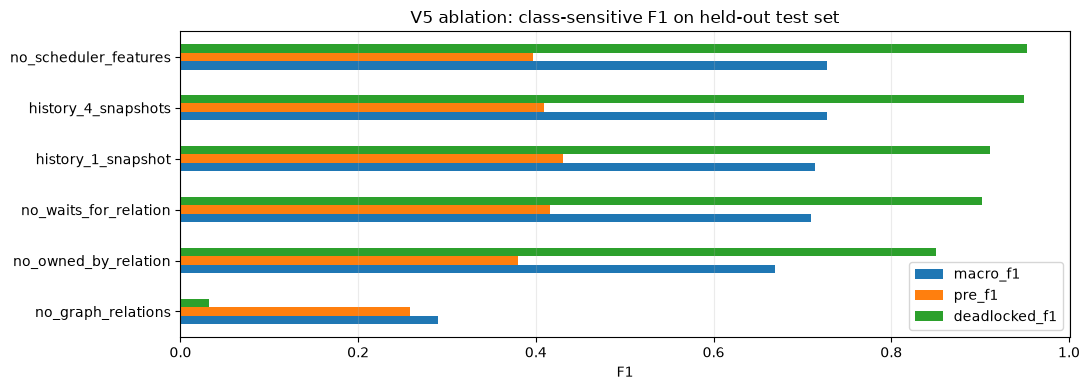

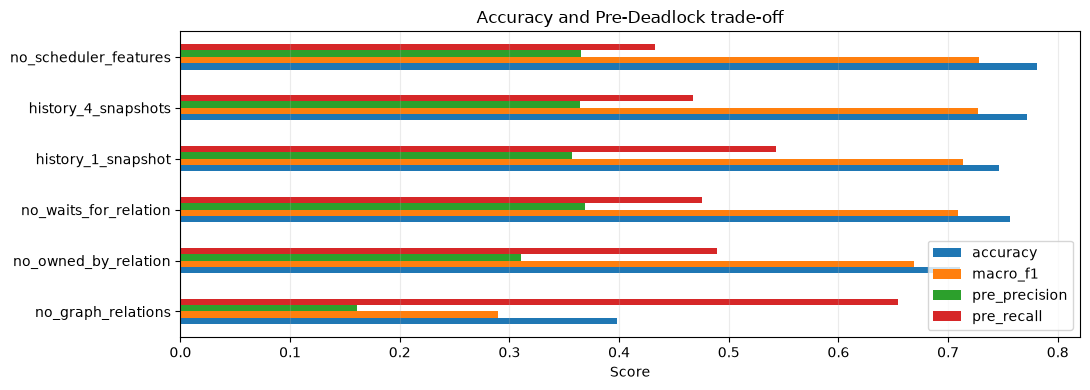

In [8]:
if not results_df.empty:
    plot_df = results_df.sort_values("macro_f1", ascending=True)
    ax = plot_df.plot(
        x="variant", y=["macro_f1", "pre_f1", "deadlocked_f1"],
        kind="barh", figsize=(11, max(4, 0.65 * len(plot_df))),
        title="V5 ablation: class-sensitive F1 on held-out test set"
    )
    ax.set_xlabel("F1")
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()

    ax = plot_df.plot(
        x="variant", y=["accuracy", "macro_f1", "pre_precision", "pre_recall"],
        kind="barh", figsize=(11, max(4, 0.65 * len(plot_df))),
        title="Accuracy and Pre-Deadlock trade-off"
    )
    ax.set_xlabel("Score")
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()


## 5. Inspect confusion matrices

Rows are actual labels and columns are predicted labels, in the order Safe, Pre-Deadlock, Deadlocked. This is useful for determining whether an ablation harms early warning, established-deadlock recognition, or Safe-state precision.


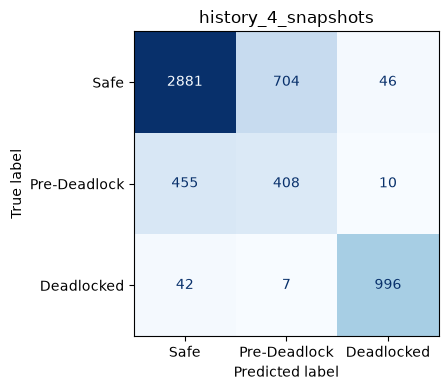

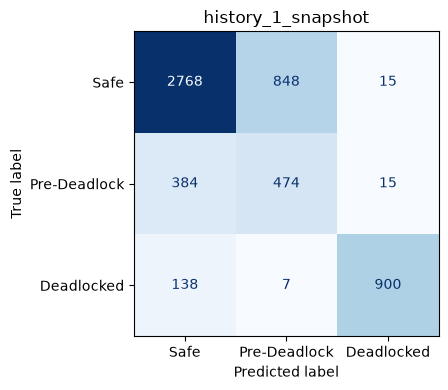

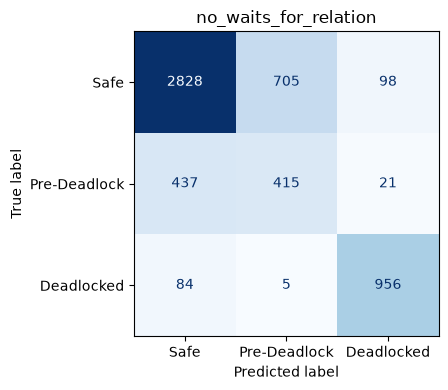

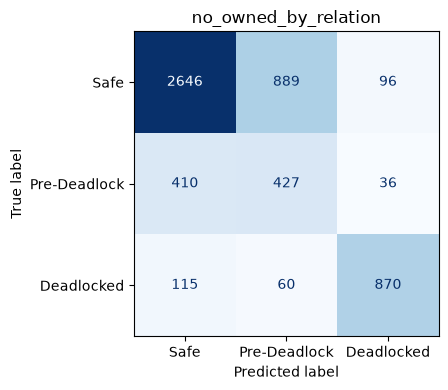

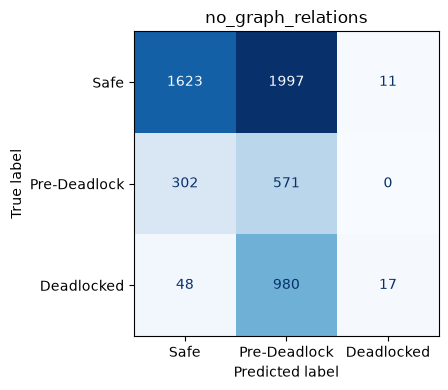

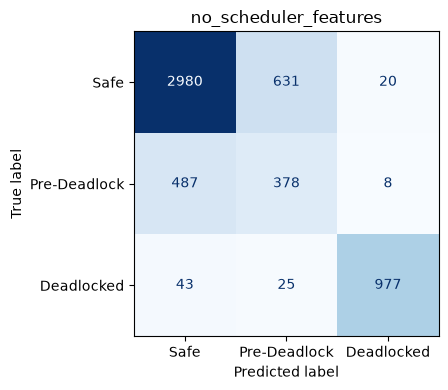

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay

for r in results:
    if not r.get("confusion_matrix"):
        continue
    cm = np.asarray(r["confusion_matrix"])
    fig, ax = plt.subplots(figsize=(4.5, 4))
    disp = ConfusionMatrixDisplay(cm, display_labels=["Safe", "Pre-Deadlock", "Deadlocked"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(r["variant"])
    plt.tight_layout()
    plt.show()


## 6. Add the previously completed controlled comparisons

The provided result file records the controlled GraphSAGE+GRU comparison and the full V5 vs no-auxiliary-risk-loss comparison. If the JSON is available in the repository, load it here and combine the reported headline results with this notebook's newly trained ablations.

**Caution:** the existing GraphSAGE+GRU baseline uses 3-class cross-entropy/argmax, while V5 uses focal multi-task losses and hierarchical thresholds. It is a useful model comparison but does not isolate architecture alone. The separately controlled no-risk-auxiliary-loss comparison is the cleaner test of auxiliary supervision.


In [10]:
# Optional: set EXISTING_CONTROLLED_RESULTS above to the path of your results JSON.
# Expected file schema follows outputs from controlled_experiments_revised.py.
existing_rows = []

if EXISTING_CONTROLLED_RESULTS:
    p = Path(EXISTING_CONTROLLED_RESULTS)
    if not p.is_absolute():
        p = ROOT / p
    existing = json.loads(p.read_text())

    e1 = existing.get("experiment_1", {})
    e1m = e1.get("test_metrics", {})
    if e1m:
        e1pc = e1m.get("per_class", {})
        existing_rows.append({
            "variant": "GraphSAGE+GRU 3-class CE/argmax (existing)",
            "description": "Existing controlled baseline; different objective/decision rule",
            "best_epoch": e1.get("best_epoch"),
            "accuracy": e1m.get("accuracy"),
            "macro_f1": e1m.get("macro_f1"),
            "pre_precision": e1pc.get("pre_deadlock", {}).get("precision"),
            "pre_recall": e1pc.get("pre_deadlock", {}).get("recall"),
            "pre_f1": e1pc.get("pre_deadlock", {}).get("f1"),
            "deadlocked_f1": e1pc.get("deadlocked", {}).get("f1"),
        })

    e2 = existing.get("experiment_2", {})
    for key, label in [
        ("full_v5", "Full V5 (existing)"),
        ("v5_without_risk_auxiliary_loss", "V5 without risk auxiliary losses (existing)")
    ]:
        block = e2.get(key, {})
        m = block.get("metrics", {})
        if m:
            pc = m.get("per_class", {})
            existing_rows.append({
                "variant": label,
                "description": "Existing controlled auxiliary-loss comparison",
                "accuracy": m.get("accuracy"),
                "macro_f1": m.get("macro_f1"),
                "pre_precision": pc.get("pre_deadlock", {}).get("precision"),
                "pre_recall": pc.get("pre_deadlock", {}).get("recall"),
                "pre_f1": pc.get("pre_deadlock", {}).get("f1"),
                "deadlocked_f1": pc.get("deadlocked", {}).get("f1"),
            })

if existing_rows:
    existing_df = pd.DataFrame(existing_rows)
    display(existing_df)
    combined_df = pd.concat([existing_df, results_df], ignore_index=True, sort=False)
    combined_df.to_csv(OUTPUT_DIR / "combined_ablation_summary.csv", index=False)
    print("Saved combined summary:", OUTPUT_DIR / "combined_ablation_summary.csv")
else:
    print("No existing JSON loaded. Set EXISTING_CONTROLLED_RESULTS to the path of the controlled-experiment results JSON.")


No existing JSON loaded. Set EXISTING_CONTROLLED_RESULTS to the path of the controlled-experiment results JSON.
